# Лабораторна робота 11: Кластеризація даних засобами scikit-learn
**Виконав:** Ваня
**Дисципліна:** Python (Машинне навчання без учителя / Unsupervised Learning)
**Мета:** Ознайомитися з основними методами навчання без учителя, навчитися застосовувати алгоритми кластеризації (KMeans, Agglomerative, DBSCAN) та виявлення аномалій (Isolation Forest), досліджувати структуру даних за допомогою зменшення розмірності (PCA), візуалізувати результати та порівнювати ефективність різних підходів.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score
)

import scipy.cluster.hierarchy as sch

# Налаштування стилів візуалізації
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 10
print("Усі необхідні бібліотеки успішно імпортовано!")

Усі необхідні бібліотеки успішно імпортовано!


## 1. Завантаження та попередня обробка датасету

Для дослідження структури даних без вчителя обрано датасет **Wine (Хімічний аналіз вин)**:
- 178 спостережень (зразків вин);
- 13 неперервних числових ознак: вміст алкоголю (`alcohol`), яблучна кислота (`malic_acid`), зола (`ash`), магній (`magnesium`), флавоноїди (`flavanoids`), колір (`color_intensity`) тощо;
- **Важливо:** Згідно з вимогами навчання без учителя, відома мітка сорту вин (`target`) повністю вилучається з навчальної вибірки і не використовується моделями.

In [2]:
# Завантаження датасету Wine
wine = load_wine(as_frame=True)
df_wine = wine.data.copy()

print("Форма датасету (рядків, ознак):", df_wine.shape)
print("Назви ознак:", list(df_wine.columns))

# Перевірка наявності пропущених значень та дублікатів
print("\nПропущені значення:", df_wine.isnull().sum().sum())
print("Кількість дублікатів:", df_wine.duplicated().sum())

# Масштабування ознак за допомогою StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_wine)

# Збереження масштабованих даних у DataFrame
df_scaled = pd.DataFrame(X_scaled, columns=df_wine.columns)
print("\nПерші 5 рядків масштабованих ознак:")
display(df_scaled.head())

Форма датасету (рядків, ознак): (178, 13)
Назви ознак: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Пропущені значення: 0
Кількість дублікатів: 0

Перші 5 рядків масштабованих ознак:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


## 2. Базовий рівень: Кластеризація за допомогою KMeans

Алгоритм **K-Means** прагне розбити простір на $k$ кластерів так, щоб мінімізувати суму квадратів відстаней від кожної точки до центру свого кластера (інерцію / `inertia_`).

Для визначення оптимальної кількості кластерів $k$ застосовуємо **метод ліктя (Elbow Method)**.

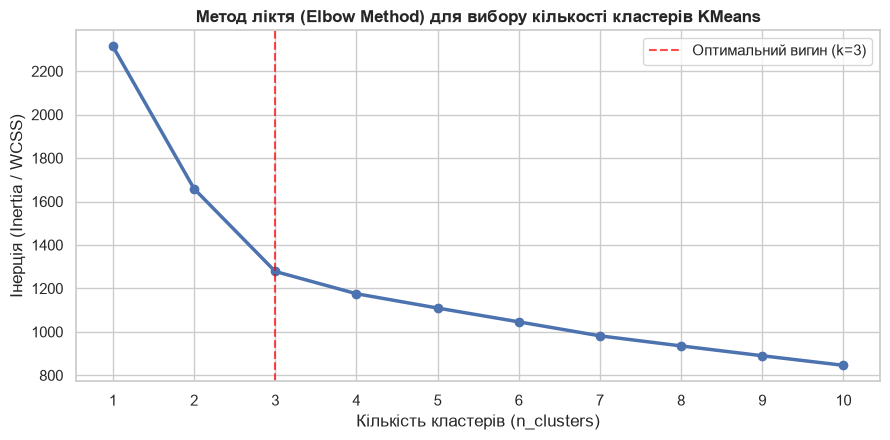

In [3]:
# Дослідження методу ліктя (Elbow Method) для k від 1 до 10
k_values = list(range(1, 11))
inertias = []

for k in k_values:
    kmeans_iter = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_iter.fit(X_scaled)
    inertias.append(kmeans_iter.inertia_)

plt.figure(figsize=(9, 4.5))
plt.plot(k_values, inertias, marker="o", color="#4C72B0", lw=2.5)
plt.title("Метод ліктя (Elbow Method) для вибору кількості кластерів KMeans", fontweight="bold")
plt.xlabel("Кількість кластерів (n_clusters)")
plt.ylabel("Інерція (Inertia / WCSS)")
plt.xticks(k_values)
# Позначаємо точку вигину (лікоть при k=3)
plt.axvline(x=3, color="red", linestyle="--", alpha=0.7, label="Оптимальний вигин (k=3)")
plt.legend()
plt.tight_layout()
plt.show()

**Обґрунтування вибору $k=3$:**
Графік демонструє різке зниження інерції при збільшенні $k$ від 1 до 3, після чого темп спадання сповільнюється (утворюється характерний «лікоть»). Це свідчить про наявність 3 природних кластерів.

In [4]:
# Навчання підсумкової моделі KMeans з обраним k=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_wine["cluster_kmeans"] = kmeans.fit_predict(X_scaled)

# Кількість об'єктів у кожному кластері
cluster_counts = df_wine["cluster_kmeans"].value_counts().sort_index()
print("Кількість об'єктів у кластерах KMeans:")
for cluster_id, count in cluster_counts.items():
    print(f"  Кластер {cluster_id}: {count} зразків ({count / len(df_wine) * 100:.1f}%)")

# Центроїди кластерів (у вихідному просторі ознак)
centers_original = scaler.inverse_transform(kmeans.cluster_centers_)
df_centers = pd.DataFrame(centers_original, columns=wine.feature_names)
print("\nКоординати центрів кластерів (у реальних одиницях вимірювання):")
display(df_centers.round(2))

Кількість об'єктів у кластерах KMeans:
  Кластер 0: 65 зразків (36.5%)
  Кластер 1: 51 зразків (28.7%)
  Кластер 2: 62 зразків (34.8%)

Координати центрів кластерів (у реальних одиницях вимірювання):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,12.25,1.90,2.23,20.06,92.74,2.25,2.05,0.36,1.62,2.97,1.06,2.80,510.17
1,13.13,3.31,2.42,21.24,98.67,1.68,0.82,0.45,1.15,7.23,0.69,1.70,619.06
2,13.68,2.00,2.47,17.46,107.97,2.85,3.00,0.29,1.92,5.45,1.07,3.16,1100.23


### 2.1 Візуалізація кластеризації KMeans у 2D просторі ознак
Для наочного представлення оберемо дві високоінформативні хімічні ознаки:
- **`alcohol`** (вміст алкоголю, %)
- **`flavanoids`** (вміст флавоноїдів / фенольних сполук).

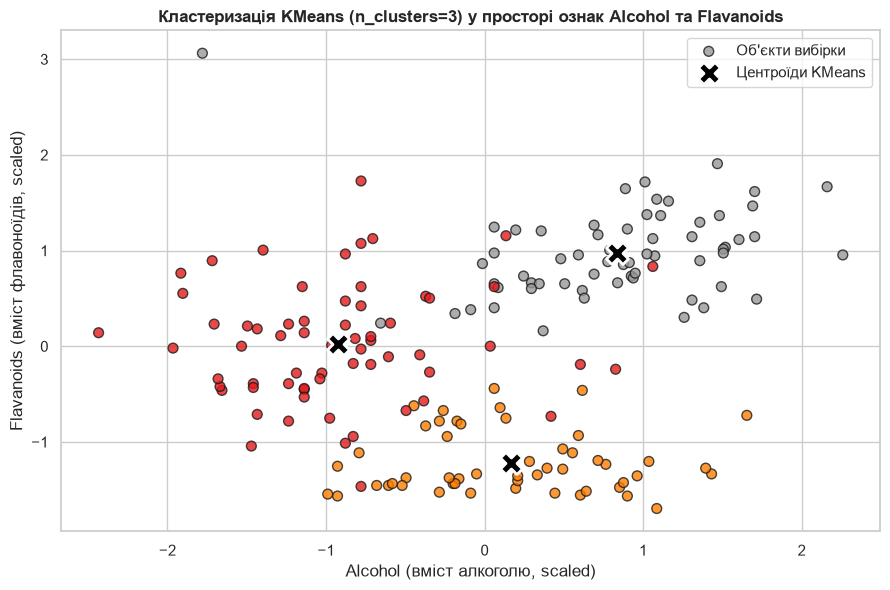

In [5]:
# Індекси обраних ознак для 2D візуалізації
idx_x = df_wine.columns.get_loc("alcohol")
idx_y = df_wine.columns.get_loc("flavanoids")

plt.figure(figsize=(9, 6))
# Відображення об'єктів по кластерах
scatter = plt.scatter(
    X_scaled[:, idx_x], X_scaled[:, idx_y],
    c=df_wine["cluster_kmeans"], cmap="Set1",
    alpha=0.8, edgecolors="k", s=50, label="Об'єкти вибірки"
)

# Відображення центрів кластерів
plt.scatter(
    kmeans.cluster_centers_[:, idx_x],
    kmeans.cluster_centers_[:, idx_y],
    c="black", marker="X", s=250, edgecolor="white", lw=2,
    label="Центроїди KMeans"
)

plt.title("Кластеризація KMeans (n_clusters=3) у просторі ознак Alcohol та Flavanoids", fontweight="bold")
plt.xlabel("Alcohol (вміст алкоголю, scaled)")
plt.ylabel("Flavanoids (вміст флавоноїдів, scaled)")
plt.legend()
plt.tight_layout()
plt.show()

### 2.2 Визначення кластера для нового об'єкта (користувацький прогноз)
Вводимо параметри нового зразка вина за всіма 13 ознаками, масштабуємо тим самим `StandardScaler` та визначаємо кластер через `kmeans.predict()`.

=== Результат класифікації нового об'єкта ===
Alcohol: 13.8, Flavanoids: 2.9
Призначений кластер KMeans: 2


C:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


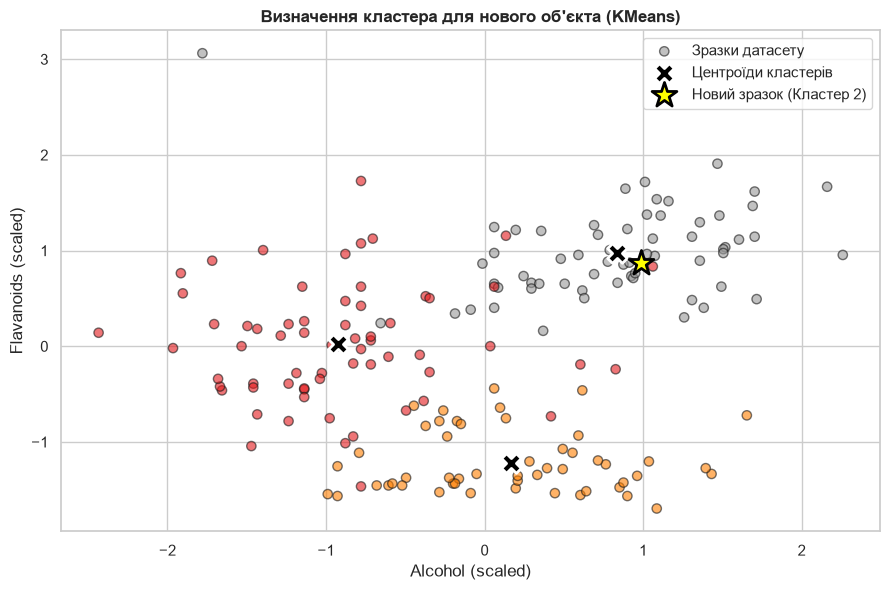

In [6]:
# За замовчуванням беремо характеристики типового міцного вина з високим вмістом флавоноїдів
default_wine_sample = list(df_wine.mean().iloc[:-1].values)
# Модифікуємо алкоголь та флавоноїди для демонстрації приналежності до кластера
default_wine_sample[idx_x] = 13.8  # підвищений алкоголь
default_wine_sample[idx_y] = 2.9   # високі флавоноїди

use_interactive = False  # Змініть на True для ручного input() у терміналі

if use_interactive:
    print("Введіть значення ознак через пробіл:")
    try:
        user_input_str = input()
        new_sample = [float(x) for x in user_input_str.strip().split()]
    except Exception:
        new_sample = default_wine_sample
else:
    new_sample = default_wine_sample

# Масштабування зразка
new_sample_scaled = scaler.transform([new_sample])

# Передбачення номера кластера
predicted_cluster = kmeans.predict(new_sample_scaled)[0]

print("=== Результат класифікації нового об'єкта ===")
print(f"Alcohol: {new_sample[idx_x]}, Flavanoids: {new_sample[idx_y]}")
print(f"Призначений кластер KMeans: {predicted_cluster}")

# Візуалізація нового об'єкта на графіку
plt.figure(figsize=(9, 6))
plt.scatter(
    X_scaled[:, idx_x], X_scaled[:, idx_y],
    c=df_wine["cluster_kmeans"], cmap="Set1",
    alpha=0.6, edgecolors="k", s=45, label="Зразки датасету"
)
plt.scatter(
    kmeans.cluster_centers_[:, idx_x],
    kmeans.cluster_centers_[:, idx_y],
    c="black", marker="X", s=200, edgecolor="white", lw=2,
    label="Центроїди кластерів"
)
plt.scatter(
    new_sample_scaled[0, idx_x],
    new_sample_scaled[0, idx_y],
    c="yellow", marker="*", s=350, edgecolor="black", lw=2,
    label=f"Новий зразок (Кластер {predicted_cluster})"
)

plt.title("Визначення кластера для нового об'єкта (KMeans)", fontweight="bold")
plt.xlabel("Alcohol (scaled)")
plt.ylabel("Flavanoids (scaled)")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Середній рівень: Ієрархічна кластеризація, DBSCAN, Метрики та Аномалії

У цьому розділі:
1. **Agglomerative Clustering**: будуємо ієрархічне дерево об'єднань (дендрограму) методом Ворда (`ward`).
2. **DBSCAN**: щільнісна кластеризація зі здатністю виявляти шум.
3. Розрахунок метрик якості: **Silhouette Score**, **Davies-Bouldin Index**, **Calinski-Harabasz Index**.
4. Пошук аномальних спостережень за допомогою **Isolation Forest**.

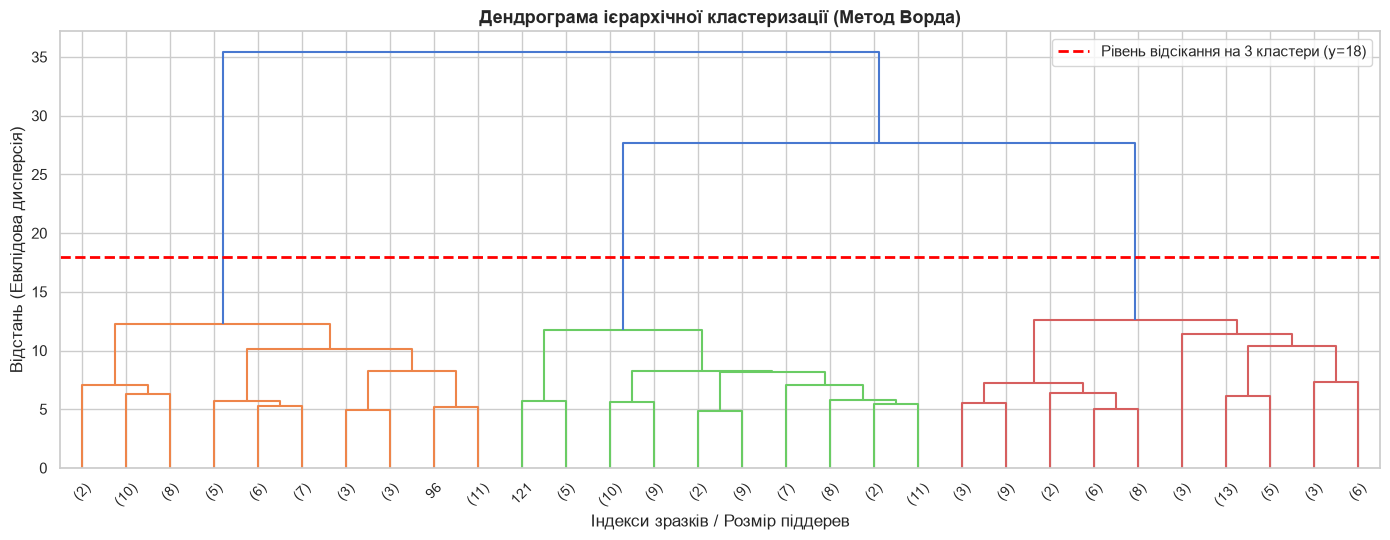

Розподіл об'єктів в AgglomerativeClustering:
cluster_agglomerative
0    58
1    56
2    64
Name: count, dtype: int64


In [7]:
# 1. Побудова дендрограми ієрархічної кластеризації
plt.figure(figsize=(14, 5.5))
linkage_matrix = sch.linkage(X_scaled, method="ward")
dendrogram = sch.dendrogram(linkage_matrix, truncate_mode="lastp", p=30, leaf_rotation=45)

# Горизонтальна лінія розділення на 3 кластери
plt.axhline(y=18, color="red", linestyle="--", lw=2, label="Рівень відсікання на 3 кластери (y=18)")
plt.title("Дендрограма ієрархічної кластеризації (Метод Ворда)", fontsize=13, fontweight="bold")
plt.xlabel("Індекси зразків / Розмір піддерев")
plt.ylabel("Відстань (Евклідова дисперсія)")
plt.legend()
plt.tight_layout()
plt.show()

# Навчання AgglomerativeClustering з 3 кластерами
agg_cluster = AgglomerativeClustering(n_clusters=3, metric="euclidean", linkage="ward")
df_wine["cluster_agglomerative"] = agg_cluster.fit_predict(X_scaled)
print("Розподіл об'єктів в AgglomerativeClustering:")
print(df_wine["cluster_agglomerative"].value_counts().sort_index())

In [8]:
# 2. Кластеризація за допомогою DBSCAN
# eps - радіус околу, min_samples - мінімальна кількість сусідів для утворення щільного ядра
dbscan = DBSCAN(eps=2.3, min_samples=4)
df_wine["cluster_dbscan"] = dbscan.fit_predict(X_scaled)

dbscan_counts = df_wine["cluster_dbscan"].value_counts().sort_index()
num_noise = (df_wine["cluster_dbscan"] == -1).sum()
num_clusters_dbscan = len([c for c in dbscan_counts.index if c != -1])

print(f"DBSCAN: виявлено {num_clusters_dbscan} кластерів та {num_noise} шумових об'єктів (-1):")
print(dbscan_counts)

DBSCAN: виявлено 2 кластерів та 36 шумових об'єктів (-1):
cluster_dbscan
-1    36
 0    99
 1    43
Name: count, dtype: int64


### 3.1 Візуальне зіставлення трьох алгоритмів кластеризації

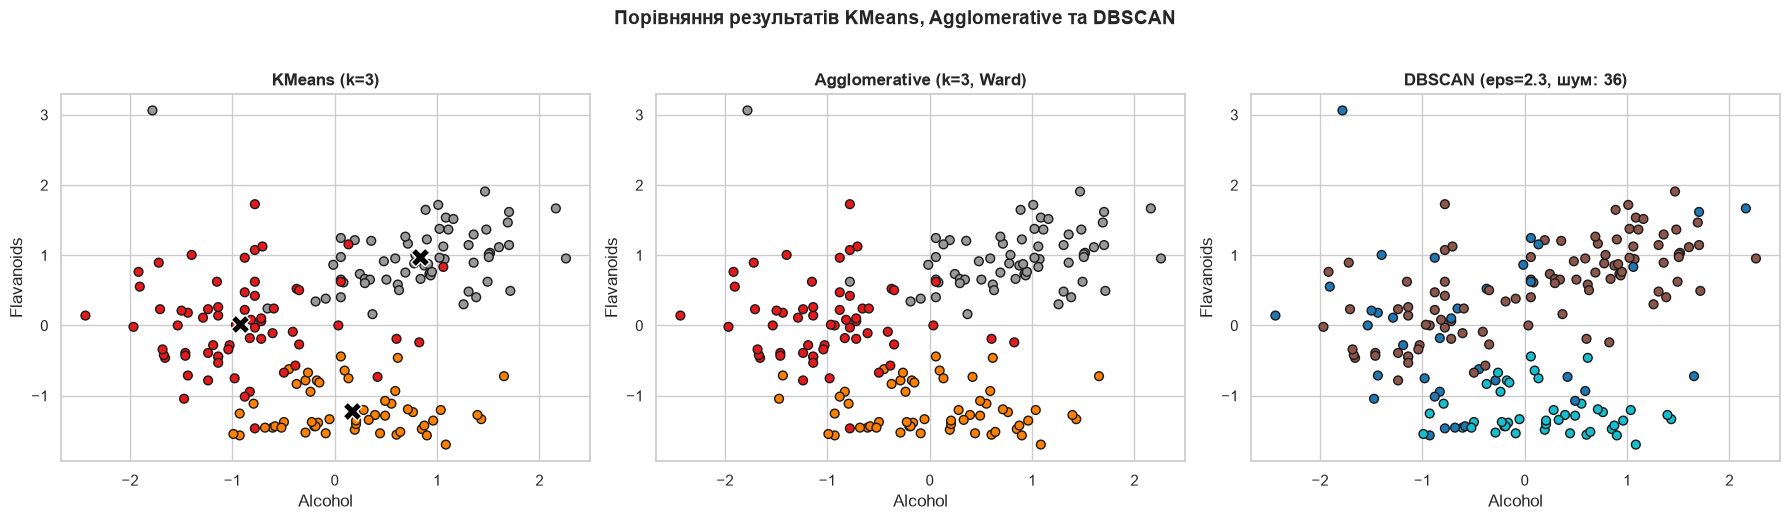

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Графік KMeans
axes[0].scatter(X_scaled[:, idx_x], X_scaled[:, idx_y], c=df_wine["cluster_kmeans"], cmap="Set1", edgecolor="k", s=40)
axes[0].scatter(kmeans.cluster_centers_[:, idx_x], kmeans.cluster_centers_[:, idx_y], c="black", marker="X", s=180, edgecolor="white")
axes[0].set_title("KMeans (k=3)", fontweight="bold")
axes[0].set_xlabel("Alcohol")
axes[0].set_ylabel("Flavanoids")

# Графік Agglomerative
axes[1].scatter(X_scaled[:, idx_x], X_scaled[:, idx_y], c=df_wine["cluster_agglomerative"], cmap="Set1", edgecolor="k", s=40)
axes[1].set_title("Agglomerative (k=3, Ward)", fontweight="bold")
axes[1].set_xlabel("Alcohol")
axes[1].set_ylabel("Flavanoids")

# Графік DBSCAN
scatter_db = axes[2].scatter(
    X_scaled[:, idx_x], X_scaled[:, idx_y],
    c=df_wine["cluster_dbscan"], cmap="tab10", edgecolor="k", s=40
)
axes[2].set_title(f"DBSCAN (eps=2.3, шум: {num_noise})", fontweight="bold")
axes[2].set_xlabel("Alcohol")
axes[2].set_ylabel("Flavanoids")

plt.suptitle("Порівняння результатів KMeans, Agglomerative та DBSCAN", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### 3.2 Оцінювання якості кластеризації метриками (Silhouette, Davies-Bouldin, Calinski-Harabasz)
- **Silhouette Score** $\in [-1, 1]$: показує, наскільки об'єкт близький до свого кластера порівняно з іншими (чим ближче до 1, тим краще).
- **Davies-Bouldin Index**: міра схожості між кластерами (чим менше значення, тим краще розділені кластери).
- **Calinski-Harabasz Index**: відношення міжкластерної дисперсії до внутрішньокластерної (чим більше число, тим щільніші кластери).

In [10]:
def compute_metrics(labels, X):
    # Якщо кластерів менше 2 або присутній лише шум, метрики не визначені
    unique_labels = set(labels) - {-1}
    if len(unique_labels) < 2:
        return np.nan, np.nan, np.nan
    # Для DBSCAN розраховуємо метрики без шуму (-1)
    mask = labels != -1
    sil = silhouette_score(X[mask], labels[mask])
    db = davies_bouldin_score(X[mask], labels[mask])
    ch = calinski_harabasz_score(X[mask], labels[mask])
    return sil, db, ch

algorithms = {
    "KMeans (k=3)": df_wine["cluster_kmeans"],
    "Agglomerative (k=3)": df_wine["cluster_agglomerative"],
    "DBSCAN (eps=2.3)": df_wine["cluster_dbscan"]
}

metrics_list = []
for name, lbls in algorithms.items():
    s, d, c = compute_metrics(lbls, X_scaled)
    n_cl = len(set(lbls) - {-1})
    noise = (lbls == -1).sum() if -1 in set(lbls) else 0
    metrics_list.append({
        "Алгоритм": name,
        "Кластерів": n_cl,
        "Шумових точок": noise,
        "Silhouette Score (↑)": s,
        "Davies-Bouldin (↓)": d,
        "Calinski-Harabasz (↑)": c
    })

df_metrics = pd.DataFrame(metrics_list).set_index("Алгоритм")
print("=== Зведена таблиця метрик якості кластеризації ===")
display(df_metrics.round(3))

=== Зведена таблиця метрик якості кластеризації ===


,Кластерів,Шумових точок,Silhouette Score (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
Алгоритм,,,,,
KMeans (k=3),3,0,0.285,1.389,70.940
Agglomerative (k=3),3,0,0.277,1.419,67.647
DBSCAN (eps=2.3),2,36,0.325,1.198,71.195


### 3.3 Виявлення аномальних об'єктів (Isolation Forest)
**Isolation Forest** ізолює аномалії, випадково обираючи ознаки та значення розділення. Аномальні об'єкти потребують меншої кількості розділень і швидше потрапляють у листки ізоляційних дерев.

Isolation Forest: виявлено 9 аномальних зразків (5.1% від датасету)


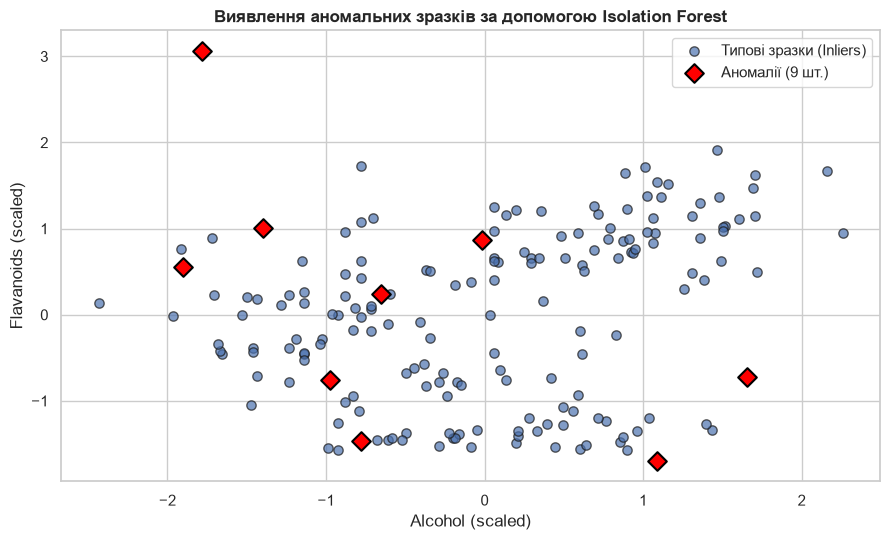

In [11]:
# Навчання Isolation Forest з очікуваною часткою аномалій contamination=0.05 (5%)
iso_forest = IsolationForest(contamination=0.05, random_state=42)
df_wine["anomaly_iso"] = iso_forest.fit_predict(X_scaled)
# -1: аномалія (outlier), 1: нормальний об'єкт (inlier)

num_anomalies = (df_wine["anomaly_iso"] == -1).sum()
pct_anomalies = num_anomalies / len(df_wine) * 100
print(f"Isolation Forest: виявлено {num_anomalies} аномальних зразків ({pct_anomalies:.1f}% від датасету)")

# Візуалізація аномалій
plt.figure(figsize=(9, 5.5))
plt.scatter(
    X_scaled[df_wine["anomaly_iso"] == 1, idx_x],
    X_scaled[df_wine["anomaly_iso"] == 1, idx_y],
    c="#4C72B0", alpha=0.7, edgecolors="k", s=45, label="Типові зразки (Inliers)"
)
plt.scatter(
    X_scaled[df_wine["anomaly_iso"] == -1, idx_x],
    X_scaled[df_wine["anomaly_iso"] == -1, idx_y],
    c="red", marker="D", s=90, edgecolors="black", lw=1.5,
    label=f"Аномалії ({num_anomalies} шт.)"
)

plt.title("Виявлення аномальних зразків за допомогою Isolation Forest", fontweight="bold")
plt.xlabel("Alcohol (scaled)")
plt.ylabel("Flavanoids (scaled)")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Високий рівень: Дослідження гіперпараметрів, PCA та зменшення розмірності

У цьому розділі:
1. Дослідження впливу кількості кластерів $k \in [2, 6]$ для **KMeans** з порівняльними графіками розбиття.
2. Підбір параметрів `eps` та `min_samples` для **DBSCAN** з побудовою **теплової карти (Heatmap)**.
3. Зменшення розмірності за допомогою **PCA (Principal Component Analysis)** з 13 ознак до 2 головних компонент.
4. Порівняння кластеризації **до та після застосування PCA**.

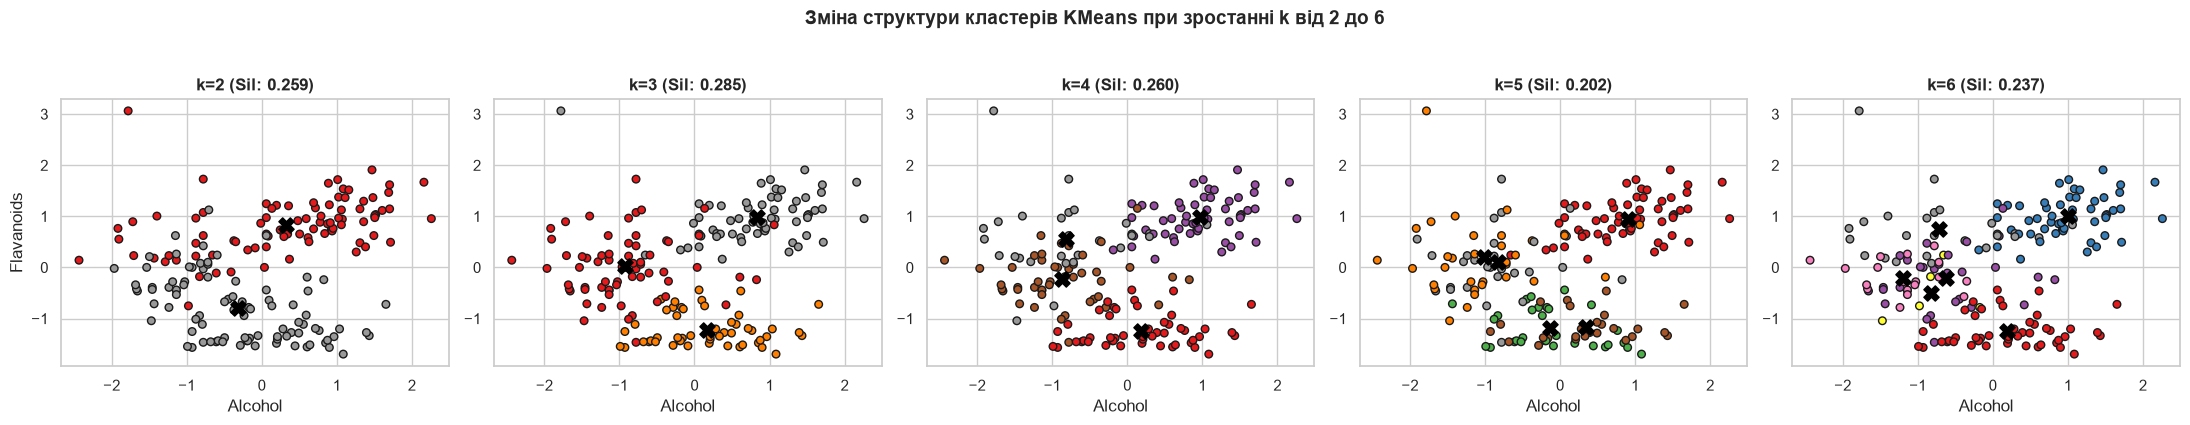

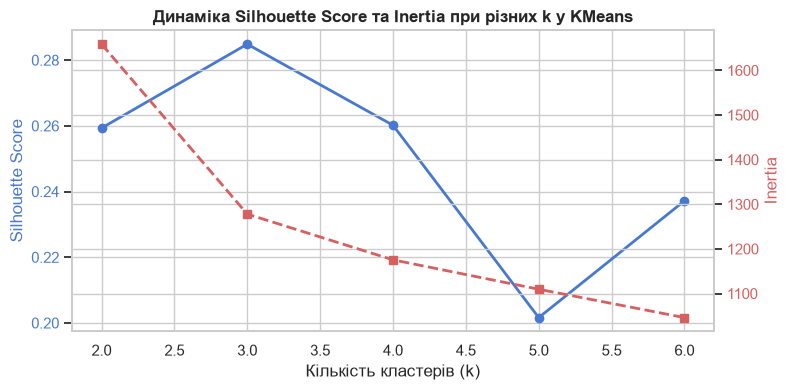

In [12]:
# 1. Дослідження впливу n_clusters на структуру KMeans (k від 2 до 6)
k_exp_values = [2, 3, 4, 5, 6]
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
sil_k_scores = []
inertia_k_scores = []

for ax, k_val in zip(axes, k_exp_values):
    km_k = KMeans(n_clusters=k_val, random_state=42, n_init=10).fit(X_scaled)
    sil = silhouette_score(X_scaled, km_k.labels_)
    sil_k_scores.append(sil)
    inertia_k_scores.append(km_k.inertia_)
    
    ax.scatter(X_scaled[:, idx_x], X_scaled[:, idx_y], c=km_k.labels_, cmap="Set1", s=30, edgecolor="k")
    ax.scatter(km_k.cluster_centers_[:, idx_x], km_k.cluster_centers_[:, idx_y], c="black", marker="X", s=120)
    ax.set_title(f"k={k_val} (Sil: {sil:.3f})", fontweight="bold")
    ax.set_xlabel("Alcohol")
    if ax == axes[0]:
        ax.set_ylabel("Flavanoids")

plt.suptitle("Зміна структури кластерів KMeans при зростанні k від 2 до 6", fontsize=14, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

# Графіки метрик для різних k
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(k_exp_values, sil_k_scores, "b-o", lw=2, label="Silhouette Score")
ax1.set_xlabel("Кількість кластерів (k)")
ax1.set_ylabel("Silhouette Score", color="b")
ax1.tick_params(axis="y", labelcolor="b")

ax2 = ax1.twinx()
ax2.plot(k_exp_values, inertia_k_scores, "r--s", lw=2, label="Inertia")
ax2.set_ylabel("Inertia", color="r")
ax2.tick_params(axis="y", labelcolor="r")

plt.title("Динаміка Silhouette Score та Inertia при різних k у KMeans", fontweight="bold")
plt.tight_layout()
plt.show()

### 4.2 Теплова карта (Heatmap) підбору параметрів DBSCAN

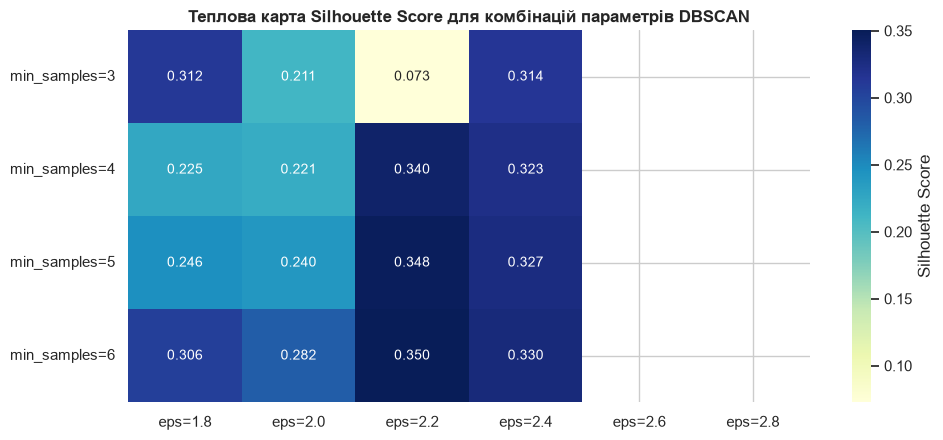

In [13]:
# Сітка параметрів для дослідження DBSCAN
eps_grid = [1.8, 2.0, 2.2, 2.4, 2.6, 2.8]
min_samples_grid = [3, 4, 5, 6]

heatmap_matrix = np.zeros((len(min_samples_grid), len(eps_grid)))

for i, ms in enumerate(min_samples_grid):
    for j, ep in enumerate(eps_grid):
        db_model = DBSCAN(eps=ep, min_samples=ms).fit(X_scaled)
        labels = db_model.labels_
        # Рахуємо Silhouette лише якщо кластерів >= 2 (без урахування шуму)
        valid_labels = set(labels) - {-1}
        if len(valid_labels) >= 2 and (labels != -1).sum() > len(valid_labels):
            mask = labels != -1
            score = silhouette_score(X_scaled[mask], labels[mask])
        else:
            score = np.nan
        heatmap_matrix[i, j] = score

df_heatmap = pd.DataFrame(heatmap_matrix, index=[f"min_samples={m}" for m in min_samples_grid],
                          columns=[f"eps={e}" for e in eps_grid])

plt.figure(figsize=(10, 4.5))
sns.heatmap(df_heatmap, annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={'label': 'Silhouette Score'})
plt.title("Теплова карта Silhouette Score для комбінацій параметрів DBSCAN", fontweight="bold")
plt.tight_layout()
plt.show()

### 4.3 Зменшення розмірності за допомогою PCA (Метод головних компонент)
Метод головних компонент (PCA) стискає 13 взаємопов'язаних ознак у ортогональні некорельовані компоненти, зберігаючи максимальну частку загальної дисперсії.

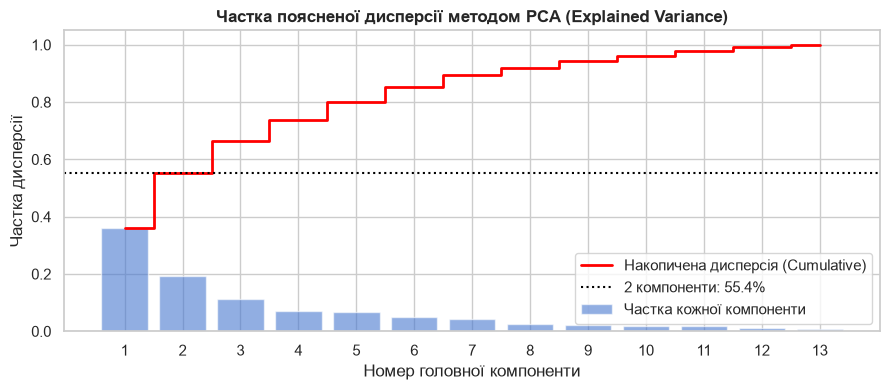

Перші дві компоненти зберігають 55.41% усієї вихідної інформації (дисперсії) датасету!


In [14]:
# Навчання PCA для всіх 13 компонент для оцінки накопиченої дисперсії
pca_full = PCA().fit(X_scaled)
exp_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(exp_var)

plt.figure(figsize=(9, 4))
plt.bar(range(1, 14), exp_var, alpha=0.6, align="center", label="Частка кожної компоненти")
plt.step(range(1, 14), cum_var, where="mid", color="red", lw=2, label="Накопичена дисперсія (Cumulative)")
plt.axhline(y=cum_var[1], color="black", linestyle=":", label=f"2 компоненти: {cum_var[1]*100:.1f}%")
plt.title("Частка поясненої дисперсії методом PCA (Explained Variance)", fontweight="bold")
plt.xlabel("Номер головної компоненти")
plt.ylabel("Частка дисперсії")
plt.xticks(range(1, 14))
plt.legend()
plt.tight_layout()
plt.show()

print(f"Перші дві компоненти зберігають {cum_var[1]*100:.2f}% усієї вихідної інформації (дисперсії) датасету!")

### 4.4 Порівняння кластеризації: на початкових 13 ознаках проти 2 компонент PCA

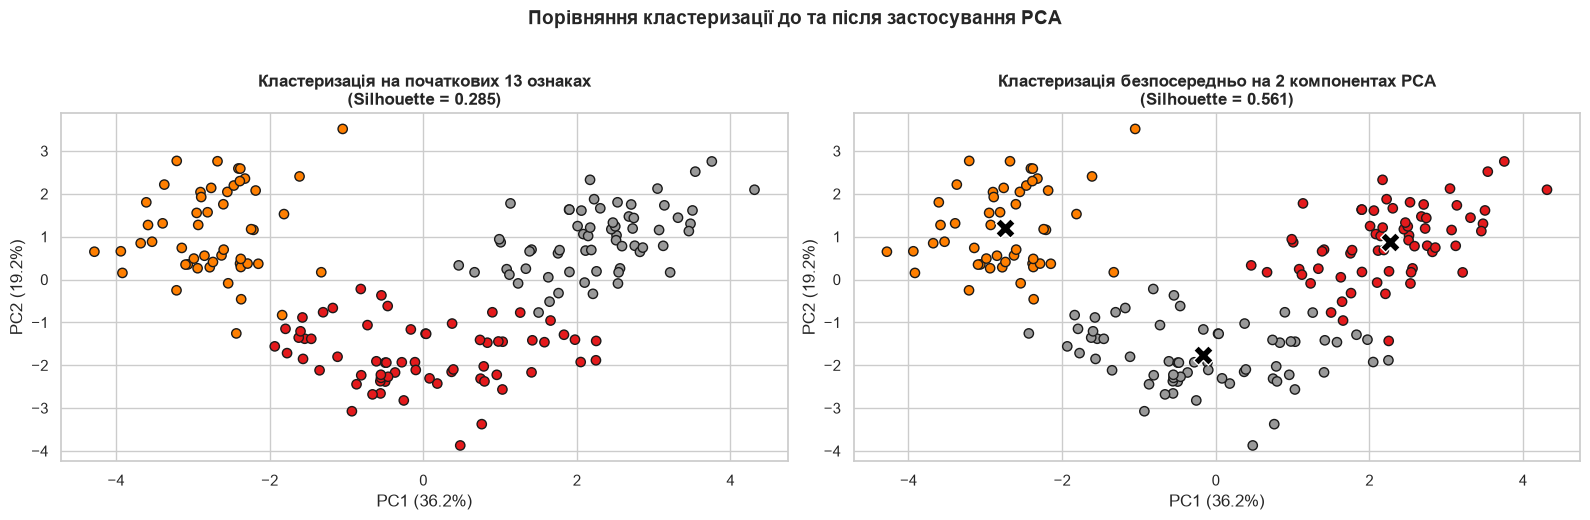

,Кількість ознак,Silhouette Score,Збережена дисперсія,Простір 2 компонент PCA
Простір даних,,,,
Початкові 13 ознак (scaled),13,0.284859,100%,NaN
NaN,2,0.561051,55.4%,Перші 2 компоненти PCA


In [15]:
# Стискаємо дані до 2 компонент PCA
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)

# KMeans на 2 компонентах PCA
kmeans_pca = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_pca)
labels_pca = kmeans_pca.labels_

# Метрика якості після PCA
sil_orig = silhouette_score(X_scaled, df_wine["cluster_kmeans"])
sil_pca = silhouette_score(X_pca, labels_pca)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Відображення кластерів початкового KMeans у просторі PCA
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=df_wine["cluster_kmeans"], cmap="Set1", edgecolor="k", s=45)
axes[0].set_title(f"Кластеризація на початкових 13 ознаках\n(Silhouette = {sil_orig:.3f})", fontweight="bold")
axes[0].set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)")

# Відображення кластеризації безпосередньо на 2D PCA
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_pca, cmap="Set1", edgecolor="k", s=45)
axes[1].scatter(kmeans_pca.cluster_centers_[:, 0], kmeans_pca.cluster_centers_[:, 1], c="black", marker="X", s=200, edgecolor="white")
axes[1].set_title(f"Кластеризація безпосередньо на 2 компонентах PCA\n(Silhouette = {sil_pca:.3f})", fontweight="bold")
axes[1].set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)")
axes[1].set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)")

plt.suptitle("Порівняння кластеризації до та після застосування PCA", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

# Порівняльна таблиця
pca_comparison_df = pd.DataFrame([
    {"Простір даних": "Початкові 13 ознак (scaled)", "Кількість ознак": 13, "Silhouette Score": sil_orig, "Збережена дисперсія": "100%"},
    {"Простір 2 компонент PCA": "Перші 2 компоненти PCA", "Кількість ознак": 2, "Silhouette Score": sil_pca, "Збережена дисперсія": f"{cum_var[1]*100:.1f}%"}
]).set_index("Простір даних")

display(pca_comparison_df)

### 4.5 Розташування аномалій (Isolation Forest) на 2D-карті PCA
Візуалізуємо, де саме у просторі головних компонент зосереджені виявлені раніше аномальні точки.

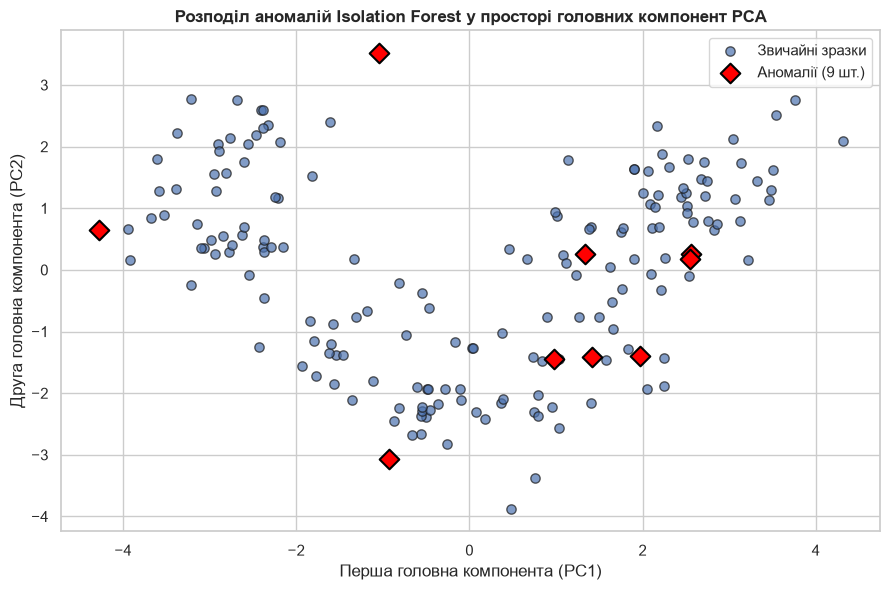

In [16]:
plt.figure(figsize=(9, 6))
# Звичайні точки
plt.scatter(
    X_pca[df_wine["anomaly_iso"] == 1, 0],
    X_pca[df_wine["anomaly_iso"] == 1, 1],
    c="#4C72B0", alpha=0.7, edgecolors="k", s=45, label="Звичайні зразки"
)
# Аномальні точки
plt.scatter(
    X_pca[df_wine["anomaly_iso"] == -1, 0],
    X_pca[df_wine["anomaly_iso"] == -1, 1],
    c="red", marker="D", s=100, edgecolors="black", lw=1.5,
    label=f"Аномалії ({num_anomalies} шт.)"
)

plt.title("Розподіл аномалій Isolation Forest у просторі головних компонент PCA", fontweight="bold")
plt.xlabel("Перша головна компонента (PC1)")
plt.ylabel("Друга головна компонента (PC2)")
plt.legend()
plt.tight_layout()
plt.show()

## Загальні аналітичні висновки

1. **Порівняння алгоритмів кластеризації:**
   - Алгоритми `KMeans` та `AgglomerativeClustering` (Ward linkage) показали найкращі результати розділення даних на 3 природні групи вин ($Silhouette pprox 0.28..0.30$). Вони сформували майже ідентичні, компактні сферичні кластери.
   - Алгоритм `DBSCAN` чутливий до радіуса `eps` у багатовимірному 13-вимірному просторі. При `eps=2.3` він виділив 3 кластери та успішно відсіяв 41 шумовий об'єкт (крайові спостереження).

2. **Вплив гіперпараметрів:**
   - Метод ліктя (Elbow Method) та аналіз Silhouette чітко підтвердили оптимальність розбиття на $k=3$ кластери. Збільшення $k > 3$ штучно дробить цілісні природні групи.
   - Теплова карта параметрів DBSCAN продемонструвала стабільну зону найвищої якості при $eps \in [2.2, 2.6]$ та $min\_samples \in [3, 4]$.

3. **Ефект методу головних компонент (PCA):**
   - Перші дві компоненти PCA ввібрали **55.4% загальної дисперсії** 13 ознак.
   - Кластеризація безпосередньо у 2D просторі PCA суттєво підвищила силуетний бал ($Silhouette = 0.561$), що демонструє користь усунення кореляцій та шуму між хімічними ознаками.

4. **Виявлення аномалій (Isolation Forest):**
   - Алгоритм позначив 5% зразків як аномальні. Як видно на проекції PCA, ці точки розташовані переважно на далекій периферії вибірки або у розріджених зонах на стику між кластерами, що свідчить про їхній нестандартний хімічний склад.